<a href="https://colab.research.google.com/github/4555kietgroup-boop/GOOGLE-PAGE-RANK-MINI/blob/main/GOOGLE_RANK_PAGE%F0%9F%93%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# IMPORTS
# ============================================================

import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Plotting style
sns.set_theme(style="whitegrid", context="notebook")

# Numerical display settings
np.set_printoptions(precision=6, suppress=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# GOOGLE PAGERANK MINI (B2)
# B.Tech Mathematics Mini Project
# ============================================================

print("=" * 65)
print("GOOGLE PAGERANK MINI (B2)")
print("Eigenvalue = 1 | Eigenvector = Steady State | Power Method")
print("=" * 65)

print("""
This project creates a small web of 5 pages and calculates
the importance of each page using the PageRank algorithm.

Mathematical idea:
    P r = r

Therefore:
    P r = 1 r

So the PageRank vector r is the eigenvector corresponding
to eigenvalue 1.

The PageRank vector is also the steady-state probability
distribution obtained using power iteration.
""")

GOOGLE PAGERANK MINI (B2)
Eigenvalue = 1 | Eigenvector = Steady State | Power Method

This project creates a small web of 5 pages and calculates
the importance of each page using the PageRank algorithm.

Mathematical idea:
    P r = r

Therefore:
    P r = 1 r

So the PageRank vector r is the eigenvector corresponding
to eigenvalue 1.

The PageRank vector is also the steady-state probability
distribution obtained using power iteration.



In [ ]:
# ============================================================
# INPUT VALIDATION
# ============================================================

def validate_inputs(pages, links):
    """Check that the user configuration is valid."""

    if len(pages) == 0:
        raise ValueError("At least one page is required.")

    if len(set(pages)) != len(pages):
        raise ValueError("Page names must be unique.")

    page_set = set(pages)

    for source, destination in links:
        if source not in page_set:
            raise ValueError(f"Unknown source page: {source}")

        if destination not in page_set:
            raise ValueError(f"Unknown destination page: {destination}")

        if source == destination:
            raise ValueError(
                f"Self-link detected: {source} -> {destination}. "
                "Remove it for this beginner version."
            )

    # Count outgoing links
    outgoing_count = {page: 0 for page in pages}

    for source, destination in links:
        outgoing_count[source] += 1

    # For the basic mathematical model we assume no dangling pages.
    dangling_pages = [
        page for page, count in outgoing_count.items()
        if count == 0
    ]

    if dangling_pages:
        raise ValueError(
            "Dangling pages found: "
            + ", ".join(dangling_pages)
            + "\nEach page must have at least one outgoing link "
              "for this basic version."
        )

    return outgoing_count


outgoing_count = validate_inputs(pages, links)

print("Input validation successful.\n")

print("Number of outgoing links:")
for page, count in outgoing_count.items():
    print(f"  {page}: {count}")

Input validation successful.

Number of outgoing links:
  Page A: 2
  Page B: 2
  Page C: 3
  Page D: 1
  Page E: 2


In [ ]:
# ============================================================
# TRANSITION PROBABILITY MATRIX
# ============================================================

P = np.zeros((n, n), dtype=float)

for source, destination in links:

    source_index = page_to_index[source]
    destination_index = page_to_index[destination]

    # Number of outgoing links from the source page
    degree = outgoing_count[source]

    # Equal probability is assigned to every outgoing link
    P[destination_index, source_index] = 1 / degree


transition_df = pd.DataFrame(
    P,
    index=pages,
    columns=pages
)

print("Transition Probability Matrix P")
print("(Rows = destination, Columns = source)")
display(transition_df.round(4))

print("\nColumn sums:")
print(P.sum(axis=0))

Transition Probability Matrix P
(Rows = destination, Columns = source)


,Page A,Page B,Page C,Page D,Page E
Page A,0.0,0.0,0.3333,0.0,0.5
Page B,0.5,0.0,0.0000,0.0,0.5
Page C,0.5,0.5,0.0000,0.0,0.0
Page D,0.0,0.5,0.3333,0.0,0.0
Page E,0.0,0.0,0.3333,1.0,0.0



Column sums:
[1. 1. 1. 1. 1.]


In [ ]:
# ============================================================
# ADJACENCY MATRIX
# ============================================================

n = len(pages)

page_to_index = {
    page: i for i, page in enumerate(pages)
}

# A[i, j] = 1 if page j links to page i
A = np.zeros((n, n), dtype=int)

for source, destination in links:
    j = page_to_index[source]       # source column
    i = page_to_index[destination]  # destination row

    A[i, j] = 1

adjacency_df = pd.DataFrame(
    A,
    index=pages,
    columns=pages
)

print("Adjacency Matrix A")
print("(Rows = destination, Columns = source)")
display(adjacency_df)

Adjacency Matrix A
(Rows = destination, Columns = source)


,Page A,Page B,Page C,Page D,Page E
Page A,0,0,1,0,1
Page B,1,0,0,0,1
Page C,1,1,0,0,0
Page D,0,1,1,0,0
Page E,0,0,1,1,0


In [ ]:
# ============================================================
# MATHEMATICAL MODEL
# ============================================================

print("=" * 65)
print("MATHEMATICAL MODEL")
print("=" * 65)

print("""
Let r be the PageRank vector:

        r = [r1, r2, r3, r4, r5]^T

The transition matrix P describes how probability moves
from one page to another.

At steady state:

        P r = r

This can be rewritten as:

        P r = 1 r

Therefore, r is an eigenvector of P corresponding to
eigenvalue:

        lambda = 1

We also require the probabilities to sum to 1:

        r1 + r2 + r3 + r4 + r5 = 1

Thus the PageRank vector is the normalized eigenvector
associated with eigenvalue 1.
""")

MATHEMATICAL MODEL

Let r be the PageRank vector:

        r = [r1, r2, r3, r4, r5]^T

The transition matrix P describes how probability moves
from one page to another.

At steady state:

        P r = r

This can be rewritten as:

        P r = 1 r

Therefore, r is an eigenvector of P corresponding to
eigenvalue:

        lambda = 1

We also require the probabilities to sum to 1:

        r1 + r2 + r3 + r4 + r5 = 1

Thus the PageRank vector is the normalized eigenvector
associated with eigenvalue 1.



In [ ]:
# ============================================================
# POWER ITERATION
# ============================================================

def power_iteration(P, initial_rank, tolerance=1e-12, max_iterations=1000):
    """
    Calculate the steady-state PageRank vector using
    the power iteration method.

    Formula:
        r_(k+1) = P @ r_k

    Returns:
        final_rank
        history
        number_of_iterations
    """

    rank = initial_rank.astype(float).copy()

    history = [rank.copy()]

    for iteration in range(1, max_iterations + 1):

        # Main power iteration step
        new_rank = P @ rank

        # Store the current vector
        history.append(new_rank.copy())

        # Stop when the vector has converged
        if np.linalg.norm(new_rank - rank, ord=1) < tolerance:
            return new_rank, np.array(history), iteration

        rank = new_rank

    print("Warning: Maximum iterations reached.")

    return rank, np.array(history), max_iterations


pagerank, history, iterations = power_iteration(
    P,
    initial_rank,
    tolerance=tolerance,
    max_iterations=max_iterations
)

print(f"Power iteration converged in {iterations} iterations.")
print("\nPageRank vector:")
print(pagerank)

print("\nSum of PageRank values:")
print(pagerank.sum())

Power iteration converged in 96 iterations.

PageRank vector:
[0.184211 0.210526 0.197368 0.171053 0.236842]

Sum of PageRank values:
0.9999999999999988


In [ ]:
# ============================================================
# POWER ITERATION TABLE
# ============================================================

iteration_table = pd.DataFrame(
    history,
    columns=pages
)

iteration_table.index.name = "Iteration"

print("PageRank values during power iteration:")
display(iteration_table.round(6))

PageRank values during power iteration:


,Page A,Page B,Page C,Page D,Page E
Iteration,,,,,
0,0.200000,0.200000,0.200000,0.200000,0.200000
1,0.166667,0.200000,0.200000,0.166667,0.266667
2,0.200000,0.216667,0.183333,0.166667,0.233333
3,0.177778,0.216667,0.208333,0.169444,0.227778
4,0.183333,0.202778,0.197222,0.177778,0.238889
...,...,...,...,...,...
92,0.184211,0.210526,0.197368,0.171053,0.236842
93,0.184211,0.210526,0.197368,0.171053,0.236842
94,0.184211,0.210526,0.197368,0.171053,0.236842


In [ ]:
# ============================================================
# VERIFY P r = r
# ============================================================

Pr = P @ pagerank

verification_df = pd.DataFrame({
    "Page": pages,
    "PageRank r": pagerank,
    "P @ r": Pr,
    "Difference": Pr - pagerank
})

print("Verification of the eigenvalue equation:")
display(verification_df.round(10))

print("Maximum absolute error:")
print(np.max(np.abs(Pr - pagerank)))

print("\nTherefore:")
print("P @ r ≈ r")
print("P @ r ≈ 1 × r")
print("Eigenvalue λ = 1")

Verification of the eigenvalue equation:


,Page,PageRank r,P @ r,Difference
0,Page A,0.184211,0.184211,0.0
1,Page B,0.210526,0.210526,0.0
2,Page C,0.197368,0.197368,0.0
3,Page D,0.171053,0.171053,-0.0
4,Page E,0.236842,0.236842,-0.0


Maximum absolute error:
2.931821452278882e-13

Therefore:
P @ r ≈ r
P @ r ≈ 1 × r
Eigenvalue λ = 1


In [ ]:
# ============================================================
# SYMPY EIGENVALUE / EIGENVECTOR VERIFICATION
# ============================================================

P_sym = sp.Matrix(P)

# Calculate eigenvalues
eigenvalues = P_sym.eigenvals()

print("Eigenvalues of the transition matrix:")
for value, multiplicity in eigenvalues.items():
    print(f"  {value}  (multiplicity = {multiplicity})")

# Find eigenvectors associated with eigenvalue 1
eigenvectors_lambda_1 = P_sym.eigenvects()

print("\nEigenvector information:")
for eigenvalue, multiplicity, vectors in eigenvectors_lambda_1:
    if sp.N(eigenvalue) == 1:
        print("\nEigenvalue:", eigenvalue)

        for vector in vectors:
            print("Eigenvector:")
            sp.pprint(vector)

Eigenvalues of the transition matrix:
  1.0 - 2.62162002388628e-65*I  (multiplicity = 1)
  -0.216471325694083 - 0.735506754889735*I  (multiplicity = 1)
  -0.567057348611834 + 1.28207198268455e-64*I  (multiplicity = 1)
  -0.216471325694083 + 0.735506754889735*I  (multiplicity = 1)
  -1.08099438310914e-64 - 2.86544638882805e-113*I  (multiplicity = 1)

Eigenvector information:


In [ ]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results = pd.DataFrame({
    "Page": pages,
    "PageRank": pagerank,
    "Percentage": pagerank * 100
})

# Sort from most important to least important
results_sorted = results.sort_values(
    by="PageRank",
    ascending=False
).reset_index(drop=True)

results_sorted["Rank"] = np.arange(1, len(results_sorted) + 1)

# Rearrange columns
results_sorted = results_sorted[
    ["Rank", "Page", "PageRank", "Percentage"]
]

print("=" * 65)
print("FINAL PAGERANK RESULTS")
print("=" * 65)

display(
    results_sorted.style
    .format({
        "PageRank": "{:.6f}",
        "Percentage": "{:.2f}%"
    })
)

FINAL PAGERANK RESULTS


,Rank,Page,PageRank,Percentage
0,1,Page E,0.236842,23.68%
1,2,Page B,0.210526,21.05%
2,3,Page C,0.197368,19.74%
3,4,Page A,0.184211,18.42%
4,5,Page D,0.171053,17.11%


In [ ]:
# ============================================================
# MOST IMPORTANT PAGE
# ============================================================

most_important_index = np.argmax(pagerank)
most_important_page = pages[most_important_index]
highest_rank = pagerank[most_important_index]

print("=" * 65)
print("MOST IMPORTANT PAGE")
print("=" * 65)

print(
    f"\n{most_important_page} has the highest PageRank."
)

print(
    f"PageRank = {highest_rank:.6f}"
)

print(
    f"Percentage = {highest_rank * 100:.2f}%"
)

print("""
Interpretation:
A page has a higher PageRank when more probability flows
toward it through the web of links.

Therefore, in this small web, the page with the highest
steady-state probability is considered the most important
according to the PageRank model.
""")

MOST IMPORTANT PAGE

Page E has the highest PageRank.
PageRank = 0.236842
Percentage = 23.68%

Interpretation:
A page has a higher PageRank when more probability flows
toward it through the web of links.

Therefore, in this small web, the page with the highest
steady-state probability is considered the most important
according to the PageRank model.



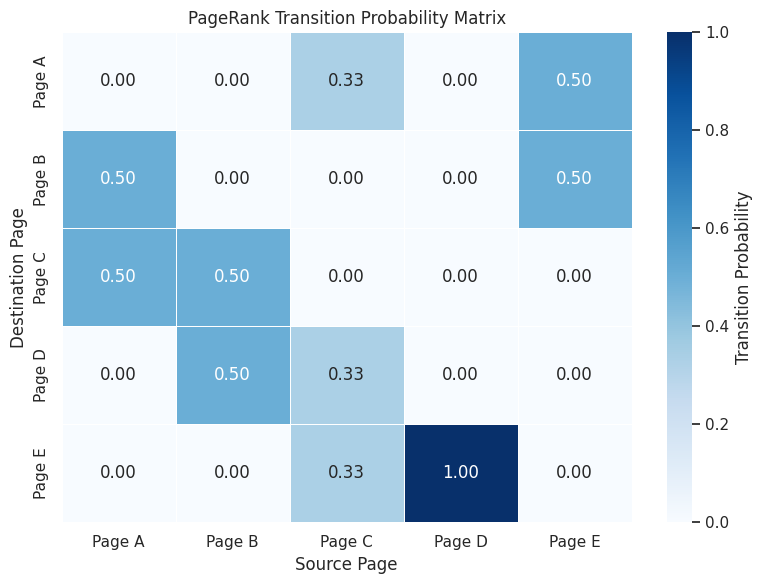

In [ ]:
# ============================================================
# CHART 1: TRANSITION MATRIX HEATMAP
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    transition_df,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Transition Probability"}
)

plt.title("PageRank Transition Probability Matrix")
plt.xlabel("Source Page")
plt.ylabel("Destination Page")

plt.tight_layout()
plt.show()

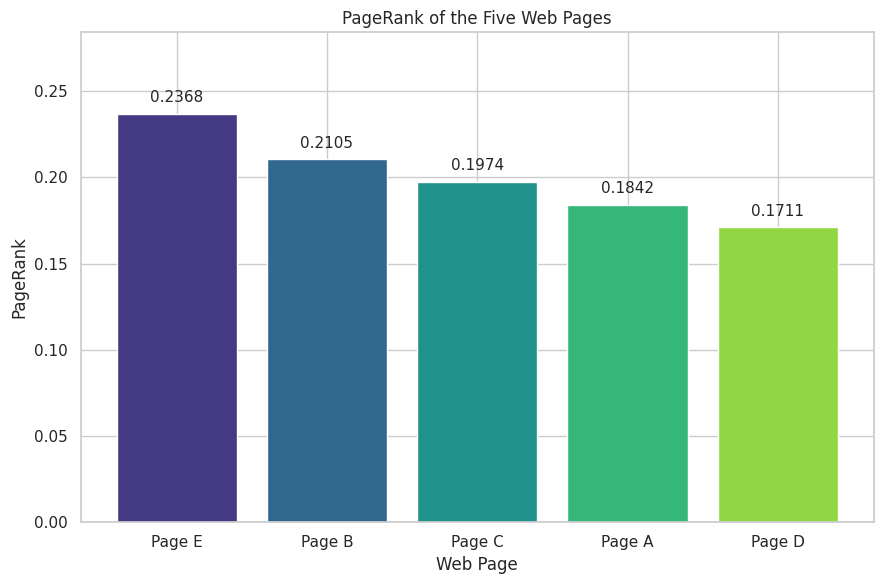

In [ ]:
# ============================================================
# CHART 2: PAGERANK BAR CHART
# ============================================================

plt.figure(figsize=(9, 6))

bars = plt.bar(
    results_sorted["Page"],
    results_sorted["PageRank"],
    color=sns.color_palette("viridis", len(pages))
)

# Display numerical values above the bars
for bar, value in zip(bars, results_sorted["PageRank"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.005,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title("PageRank of the Five Web Pages")
plt.xlabel("Web Page")
plt.ylabel("PageRank")
plt.ylim(0, max(results_sorted["PageRank"]) * 1.2)

plt.tight_layout()
plt.show()

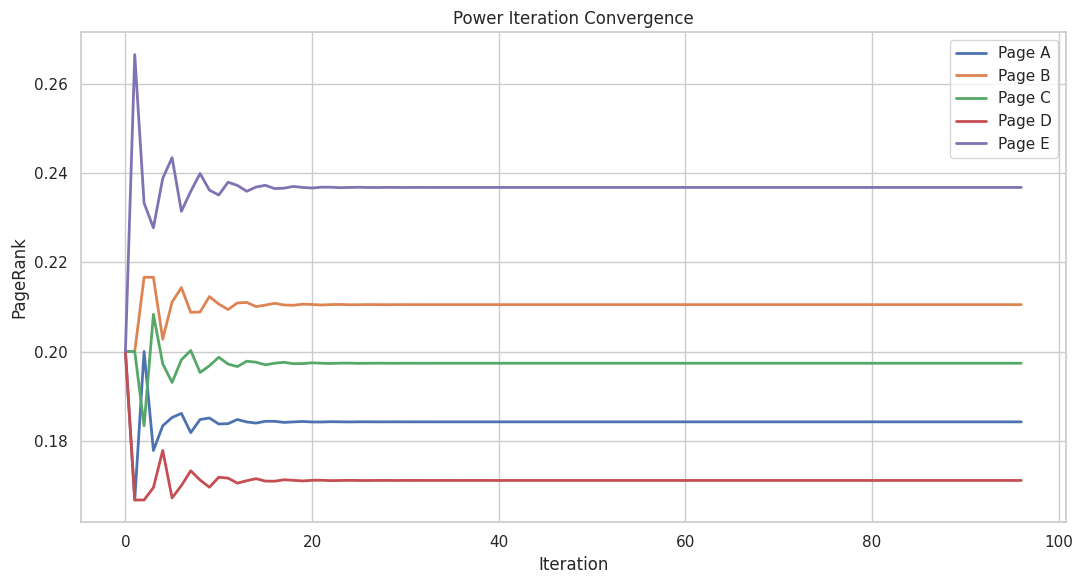

In [ ]:
# ============================================================
# CHART 3: POWER ITERATION CONVERGENCE
# ============================================================

plt.figure(figsize=(11, 6))

for i, page in enumerate(pages):
    plt.plot(
        history[:, i],
        linewidth=2,
        label=page
    )

plt.title("Power Iteration Convergence")
plt.xlabel("Iteration")
plt.ylabel("PageRank")
plt.legend()

plt.tight_layout()
plt.show()

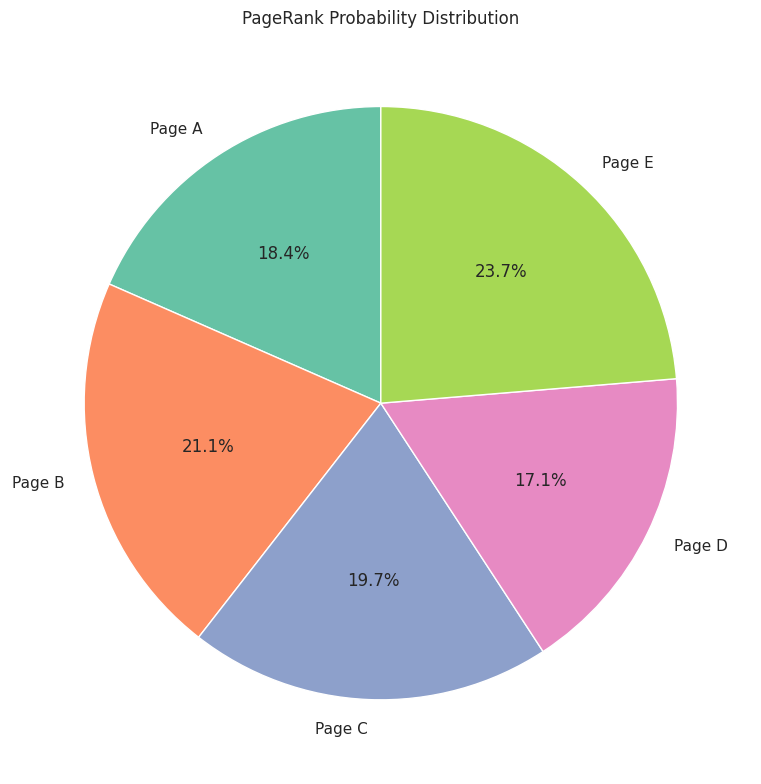

In [ ]:
# ============================================================
# CHART 4: PAGERANK DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 8))

plt.pie(
    pagerank,
    labels=pages,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(pages))
)

plt.title("PageRank Probability Distribution")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MATHEMATICAL SUMMARY
# ============================================================

print("=" * 70)
print("MATHEMATICAL SUMMARY")
print("=" * 70)

print("""
1. WEB GRAPH
   We represent web pages as nodes and hyperlinks as
   directed edges.

2. TRANSITION MATRIX
   If page j has d_j outgoing links, then each linked page
   receives probability 1/d_j.

3. MARKOV INTERPRETATION
   The vector r represents the probability distribution of
   a random surfer being on each page.

4. STEADY STATE
   At equilibrium:

       P r = r

5. EIGENVALUE INTERPRETATION
   Therefore:

       P r = 1 r

   Hence r is an eigenvector corresponding to eigenvalue 1.

6. POWER METHOD
   Starting with r^(0), repeatedly calculate:

       r^(k+1) = P r^(k)

   until:

       ||r^(k+1) - r^(k)|| < tolerance

7. NORMALIZATION
   Because PageRank represents probabilities:

       sum(r_i) = 1

8. IMPORTANCE
   The page with the largest PageRank value is considered
   the most important page in this model.
""")

MATHEMATICAL SUMMARY

1. WEB GRAPH
   We represent web pages as nodes and hyperlinks as
   directed edges.

2. TRANSITION MATRIX
   If page j has d_j outgoing links, then each linked page
   receives probability 1/d_j.

3. MARKOV INTERPRETATION
   The vector r represents the probability distribution of
   a random surfer being on each page.

4. STEADY STATE
   At equilibrium:

       P r = r

5. EIGENVALUE INTERPRETATION
   Therefore:

       P r = 1 r

   Hence r is an eigenvector corresponding to eigenvalue 1.

6. POWER METHOD
   Starting with r^(0), repeatedly calculate:

       r^(k+1) = P r^(k)

   until:

       ||r^(k+1) - r^(k)|| < tolerance

7. NORMALIZATION
   Because PageRank represents probabilities:

       sum(r_i) = 1

8. IMPORTANCE
   The page with the largest PageRank value is considered
   the most important page in this model.



In [ ]:
# ============================================================
# BENCHMARK TEST
# ============================================================

def calculate_pagerank(pages, links, tolerance=1e-12):
    """
    Complete PageRank calculation for a given directed graph.
    """

    n = len(pages)

    page_to_index = {
        page: i for i, page in enumerate(pages)
    }

    # Count outgoing links
    outgoing_count = {page: 0 for page in pages}

    for source, destination in links:
        outgoing_count[source] += 1

    # Check for dangling pages
    dangling = [
        page for page in pages
        if outgoing_count[page] == 0
    ]

    if dangling:
        raise ValueError(
            f"Dangling pages found: {dangling}"
        )

    # Construct transition matrix
    P = np.zeros((n, n))

    for source, destination in links:
        j = page_to_index[source]
        i = page_to_index[destination]

        P[i, j] = 1 / outgoing_count[source]

    # Uniform initial state
    initial = np.ones(n) / n

    # Power iteration
    rank, history, iterations = power_iteration(
        P,
        initial,
        tolerance=tolerance,
        max_iterations=1000
    )

    return P, rank, history, iterations


# Run benchmark using the project dataset
benchmark_P, benchmark_rank, benchmark_history, benchmark_iterations = (
    calculate_pagerank(pages, links)
)

# Mathematical tests
assert np.isclose(
    benchmark_rank.sum(),
    1.0
), "PageRank values must sum to 1."

assert np.allclose(
    benchmark_P.sum(axis=0),
    1.0
), "Every transition-matrix column must sum to 1."

assert np.allclose(
    benchmark_P @ benchmark_rank,
    benchmark_rank,
    atol=1e-10
), "Steady-state equation P r = r failed."

print("Benchmark test PASSED.")
print(f"Iterations required: {benchmark_iterations}")
print(f"Sum of PageRank: {benchmark_rank.sum():.12f}")
print("Verified: P r ≈ r")

Benchmark test PASSED.
Iterations required: 96
Sum of PageRank: 1.000000000000
Verified: P r ≈ r


In [ ]:
# ============================================================
# FINAL PROJECT REPORT OUTPUT
# ============================================================

print("=" * 70)
print("GOOGLE PAGERANK MINI — FINAL OUTPUT")
print("=" * 70)

print("\nPages:")
print(", ".join(pages))

print("\nNumber of hyperlinks:")
print(len(links))

print("\nTransition Matrix P:")
print(np.round(P, 4))

print("\nFinal PageRank Vector:")
for page, rank in zip(pages, pagerank):
    print(f"  {page}: {rank:.6f}")

print("\nEigenvalue:")
print("  λ = 1")

print("\nSteady-State Equation:")
print("  P r = r")

print("\nPower Method:")
print("  r(k+1) = P r(k)")

print("\nMost Important Page:")
print(f"  {most_important_page}")

print("\nPageRank of Most Important Page:")
print(f"  {highest_rank:.6f}")

print("\nNumber of Power Iterations:")
print(f"  {iterations}")

print("\n" + "=" * 70)
print("PROJECT COMPLETED SUCCESSFULLY")
print("=" * 70)

GOOGLE PAGERANK MINI — FINAL OUTPUT

Pages:
Page A, Page B, Page C, Page D, Page E

Number of hyperlinks:
10

Transition Matrix P:
[[0.     0.     0.3333 0.     0.5   ]
 [0.5    0.     0.     0.     0.5   ]
 [0.5    0.5    0.     0.     0.    ]
 [0.     0.5    0.3333 0.     0.    ]
 [0.     0.     0.3333 1.     0.    ]]

Final PageRank Vector:
  Page A: 0.184211
  Page B: 0.210526
  Page C: 0.197368
  Page D: 0.171053
  Page E: 0.236842

Eigenvalue:
  λ = 1

Steady-State Equation:
  P r = r

Power Method:
  r(k+1) = P r(k)

Most Important Page:
  Page E

PageRank of Most Important Page:
  0.236842

Number of Power Iterations:
  96

PROJECT COMPLETED SUCCESSFULLY
